In [2]:
import sys
sys.path.append("..")  # agar folder src bisa diimpor dari folder notebooks

import pandas as pd
from src.evaluate import muat_semua_hasil, matriks_per_fold, ringkas_per_model

pd.set_option("display.width", 200)

# Gabungkan semua tabel hasil per fold
tabel = pd.read_csv  # (placeholder agar sel ini mudah dibaca; baris berikut yang dipakai)
tabel = muat_semua_hasil("../reports/tables")
print("Jumlah baris hasil:", len(tabel))
print("\nJumlah putaran per model:")
print(tabel.groupby("model").size().to_string())

# Ringkasan: rata-rata dan simpangan baku antar fold (seed dirata-rata dulu)
ringkas = ringkas_per_model(tabel)
print("\nRingkasan semua model (urut Macro F1 tertinggi):")
print(ringkas.round(3).to_string(index=False))
ringkas.round(4).to_csv("../reports/tables/ringkasan_model.csv", index=False)

# Macro F1 per fold untuk tiap model (dirata-rata antar seed)
print("\nMacro F1 per fold:")
print(matriks_per_fold(tabel).round(3).to_string())

Jumlah baris hasil: 95

Jumlah putaran per model:
model
BiLSTM+FastText            15
E3_indobert_lr2e-5         15
E4a_indobert_lr3e-5        15
E4b_indobert_lr1e-5        15
E5_indobert_classweight    15
E6_indobert_slang          15
SVM+TF-IDF                  5

Ringkasan semua model (urut Macro F1 tertinggi):
                  model  macro_f1_mean  macro_f1_std  accuracy_mean  accuracy_std  weighted_f1_mean  weighted_f1_std
    E4b_indobert_lr1e-5          0.856         0.010          0.853         0.010             0.851            0.010
    E4a_indobert_lr3e-5          0.856         0.016          0.852         0.015             0.851            0.016
     E3_indobert_lr2e-5          0.855         0.014          0.852         0.013             0.850            0.013
      E6_indobert_slang          0.853         0.011          0.850         0.011             0.849            0.011
E5_indobert_classweight          0.852         0.013          0.849         0.012             0.847

In [3]:
import numpy as np
from scipy import stats

per_fold = matriks_per_fold(tabel)  # Macro F1 per fold, dirata-rata antar seed
N_LATIH, N_UJI = 1760, 440          # per fold: data latih (train + val) dan data uji

def bandingkan(a, b):
    """Uji berpasangan model a lawan model b pada Macro F1 per fold."""
    x, y = per_fold[a], per_fold[b]
    d = x - y
    k = len(d)
    p_t = stats.ttest_rel(x, y).pvalue
    p_w = stats.wilcoxon(x, y).pvalue  # untuk sampel kecil dihitung secara eksak
    # t-test terkoreksi Nadeau-Bengio: varians dikali (1/k + n_uji/n_latih)
    t_koreksi = d.mean() / np.sqrt((1 / k + N_UJI / N_LATIH) * d.var(ddof=1))
    p_k = 2 * stats.t.sf(abs(t_koreksi), df=k - 1)
    return {"pasangan": f"{a}  vs  {b}",
            "selisih_rata2": d.mean(),
            "fold_menang": f"{int((d > 0).sum())}/{k}",
            "p_t_berpasangan": p_t, "p_wilcoxon": p_w, "p_t_terkoreksi": p_k}

E3, SVM, BILSTM = "E3_indobert_lr2e-5", "SVM+TF-IDF", "BiLSTM+FastText"
pasangan = [(E3, SVM), (E3, BILSTM), (SVM, BILSTM),                # tiga perbandingan utama
            (E3, "E4a_indobert_lr3e-5"), (E3, "E4b_indobert_lr1e-5"),  # variasi vs dasar
            (E3, "E5_indobert_classweight"), (E3, "E6_indobert_slang")]

hasil_uji = pd.DataFrame([bandingkan(a, b) for a, b in pasangan])
print(hasil_uji.round(4).to_string(index=False))
hasil_uji.round(5).to_csv("../reports/tables/uji_signifikansi.csv", index=False)

                                       pasangan  selisih_rata2 fold_menang  p_t_berpasangan  p_wilcoxon  p_t_terkoreksi
             E3_indobert_lr2e-5  vs  SVM+TF-IDF         0.0198         5/5           0.0034      0.0625          0.0141
        E3_indobert_lr2e-5  vs  BiLSTM+FastText         0.0755         5/5           0.0019      0.0625          0.0085
                SVM+TF-IDF  vs  BiLSTM+FastText         0.0557         5/5           0.0057      0.0625          0.0227
    E3_indobert_lr2e-5  vs  E4a_indobert_lr3e-5        -0.0008         2/5           0.8953      1.0000          0.9300
    E3_indobert_lr2e-5  vs  E4b_indobert_lr1e-5        -0.0009         3/5           0.8240      0.8125          0.8819
E3_indobert_lr2e-5  vs  E5_indobert_classweight         0.0033         4/5           0.3820      0.4375          0.5487
      E3_indobert_lr2e-5  vs  E6_indobert_slang         0.0015         3/5           0.6296      0.6250          0.7456


In [1]:
# Sel: cek isi file prediksi tiga model
import pandas as pd

# Nama file prediksi tiap model (di folder reports/tables)
file_prediksi = {
    "SVM": "../reports/tables/svm_prediksi.csv",
    "BiLSTM": "../reports/tables/bilstm_prediksi.csv",
    "IndoBERT E3": "../reports/tables/E3_indobert_lr2e-5_prediksi.csv",
}

for nama, path in file_prediksi.items():
    df = pd.read_csv(path)
    print("=====", nama, "=====")
    print("Kolom      :", list(df.columns))
    print("Jumlah baris:", len(df))
    print("Seed       :", sorted(df["seed"].unique()) if "seed" in df.columns else "tidak ada kolom seed")
    print("Label      :", sorted(df["label_asli"].unique()))
    print(df.head(3))
    print()

===== SVM =====
Kolom      : ['fold', 'label_asli', 'prediksi']
Jumlah baris: 2200
Seed       : tidak ada kolom seed
Label      : ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
   fold label_asli  prediksi
0     0       fear      fear
1     0        joy  surprise
2     0      anger       joy

===== BiLSTM =====
Kolom      : ['fold', 'seed', 'label_asli', 'prediksi']
Jumlah baris: 6600
Seed       : [np.int64(42), np.int64(43), np.int64(44)]
Label      : ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
   fold  seed label_asli prediksi
0     0    42       fear     fear
1     0    42        joy      joy
2     0    42      anger      joy

===== IndoBERT E3 =====
Kolom      : ['fold', 'seed', 'label_asli', 'prediksi']
Jumlah baris: 6600
Seed       : [np.int64(42), np.int64(43), np.int64(44)]
Label      : ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
   fold  seed label_asli  prediksi
0     0    42       fear      fear
1     0    42        joy  surprise
2  

In [2]:
# Sel: hitung confusion matrix tiga model
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Urutan kelas dibuat tetap supaya semua tabel sama
kelas = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]

def hitung_cm(df):
    """Confusion matrix (jumlah). Jika ada kolom seed, dirata-rata antar seed."""
    if "seed" in df.columns:
        daftar = []
        for seed, bagian in df.groupby("seed"):
            daftar.append(confusion_matrix(bagian["label_asli"], bagian["prediksi"], labels=kelas))
        return np.mean(daftar, axis=0)
    return confusion_matrix(df["label_asli"], df["prediksi"], labels=kelas).astype(float)

hasil_cm = {}   # menyimpan matriks tiap model untuk dipakai di sel berikutnya
for nama, path in file_prediksi.items():
    df = pd.read_csv(path)
    cm = hitung_cm(df)
    hasil_cm[nama] = cm

    # Persentase per baris (baris = emosi asli)
    cm_persen = cm / cm.sum(axis=1, keepdims=True) * 100

    print("=====", nama, "=====")
    print("Jumlah (rata-rata antar seed):")
    print(pd.DataFrame(cm, index=kelas, columns=kelas).round(1))
    print()
    print("Persen per baris (%):")
    print(pd.DataFrame(cm_persen, index=kelas, columns=kelas).round(1))
    print()

===== SVM =====
Jumlah (rata-rata antar seed):
          anger  disgust   fear    joy  sadness  surprise
anger     347.0     35.0   11.0   19.0     42.0      11.0
disgust     3.0    339.0    4.0    1.0      1.0       2.0
fear       22.0      2.0  352.0    4.0      3.0       4.0
joy        41.0      9.0   12.0  304.0     14.0      38.0
sadness    40.0      5.0    5.0    8.0    237.0       3.0
surprise   15.0      0.0    5.0    9.0      1.0     252.0

Persen per baris (%):
          anger  disgust  fear   joy  sadness  surprise
anger      74.6      7.5   2.4   4.1      9.0       2.4
disgust     0.9     96.9   1.1   0.3      0.3       0.6
fear        5.7      0.5  91.0   1.0      0.8       1.0
joy         9.8      2.2   2.9  72.7      3.3       9.1
sadness    13.4      1.7   1.7   2.7     79.5       1.0
surprise    5.3      0.0   1.8   3.2      0.4      89.4

===== BiLSTM =====
Jumlah (rata-rata antar seed):
          anger  disgust   fear    joy  sadness  surprise
anger     315.7     37.

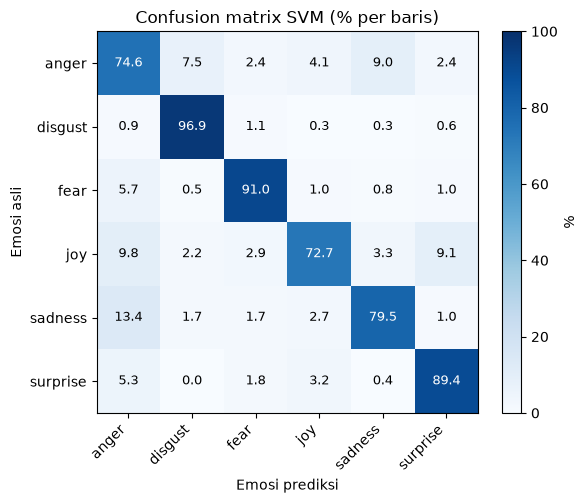

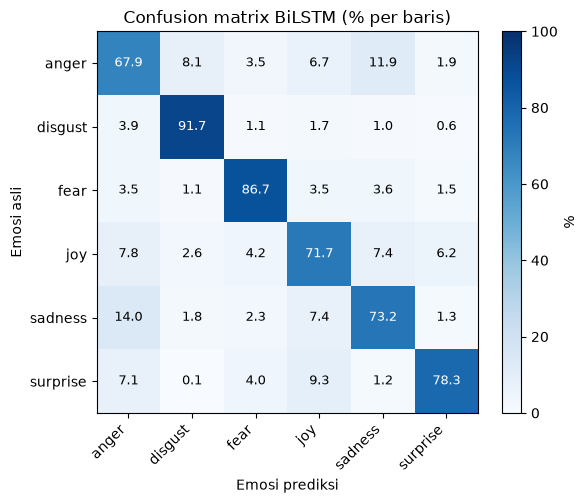

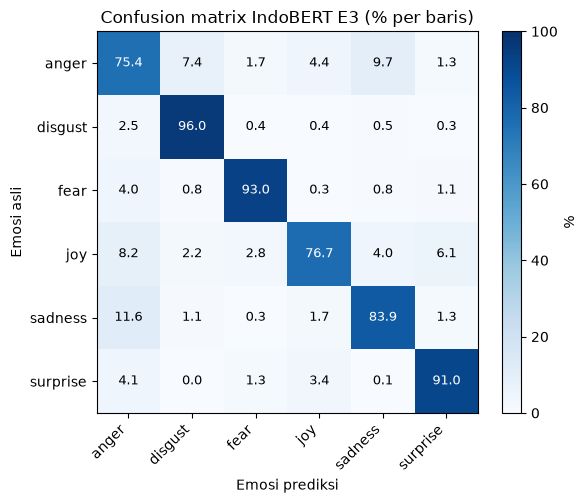

In [3]:
# Sel: simpan heatmap confusion matrix (persen per baris)
import matplotlib.pyplot as plt

# Nama file gambar untuk tiap model
nama_file = {
    "SVM": "cm_svm.png",
    "BiLSTM": "cm_bilstm.png",
    "IndoBERT E3": "cm_indobert_e3.png",
}

for nama, cm in hasil_cm.items():
    cm_persen = cm / cm.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(6, 5))
    gambar = ax.imshow(cm_persen, cmap="Blues", vmin=0, vmax=100)

    # Label sumbu
    ax.set_xticks(range(len(kelas)))
    ax.set_yticks(range(len(kelas)))
    ax.set_xticklabels(kelas, rotation=45, ha="right")
    ax.set_yticklabels(kelas)
    ax.set_xlabel("Emosi prediksi")
    ax.set_ylabel("Emosi asli")
    ax.set_title(f"Confusion matrix {nama} (% per baris)")

    # Tulis angka persen di tiap kotak; teks putih jika kotak gelap
    for i in range(len(kelas)):
        for j in range(len(kelas)):
            warna = "white" if cm_persen[i, j] > 50 else "black"
            ax.text(j, i, f"{cm_persen[i, j]:.1f}", ha="center", va="center", color=warna, fontsize=9)

    fig.colorbar(gambar, ax=ax, label="%")
    fig.tight_layout()
    fig.savefig(f"../reports/figures/{nama_file[nama]}", dpi=200)
    plt.show()

In [4]:
# Sel: precision, recall, F1 per emosi dari file hasil per fold
import pandas as pd

file_hasil = {
    "SVM": "../reports/tables/svm_per_fold.csv",
    "BiLSTM": "../reports/tables/bilstm_per_fold_seed.csv",
    "IndoBERT E3": "../reports/tables/E3_indobert_lr2e-5_per_fold_seed.csv",
}

baris = []
for nama, path in file_hasil.items():
    df = pd.read_csv(path)
    for emosi in kelas:
        baris.append({
            "model": nama,
            "emosi": emosi,
            "precision": df[f"precision_{emosi}"].mean(),
            "recall": df[f"recall_{emosi}"].mean(),
            "f1": df[f"f1_{emosi}"].mean(),
        })

tabel_kelas = pd.DataFrame(baris)

# Tampilkan per metrik: baris = emosi, kolom = model
for metrik in ["precision", "recall", "f1"]:
    print("=====", metrik.upper(), "=====")
    print(tabel_kelas.pivot(index="emosi", columns="model", values=metrik).loc[kelas].round(3))
    print()

# Simpan untuk laporan
tabel_kelas.to_csv("../reports/tables/metrik_per_kelas.csv", index=False)
print("Tersimpan: reports/tables/metrik_per_kelas.csv")

===== PRECISION =====
model     BiLSTM  IndoBERT E3    SVM
emosi                               
anger      0.726        0.774  0.743
disgust    0.848        0.871  0.871
fear       0.865        0.934  0.908
joy        0.764        0.895  0.883
sadness    0.682        0.790  0.795
surprise   0.832        0.865  0.813

===== RECALL =====
model     BiLSTM  IndoBERT E3    SVM
emosi                               
anger      0.679        0.754  0.746
disgust    0.917        0.960  0.969
fear       0.867        0.930  0.910
joy        0.717        0.767  0.727
sadness    0.731        0.839  0.795
surprise   0.783        0.910  0.894

===== F1 =====
model     BiLSTM  IndoBERT E3    SVM
emosi                               
anger      0.698        0.762  0.744
disgust    0.880        0.913  0.917
fear       0.862        0.932  0.907
joy        0.735        0.825  0.797
sadness    0.699        0.811  0.794
surprise   0.802        0.886  0.852

Tersimpan: reports/tables/metrik_per_kelas.csv


In [5]:
# Sel: cek apakah urutan baris prediksi sama dengan data uji di folds.csv
import pandas as pd

data = pd.read_csv("../data/processed/emotweetid_preprocessed.csv")
folds = pd.read_csv("../data/processed/folds.csv")
pred = pd.read_csv("../reports/tables/E3_indobert_lr2e-5_prediksi.csv")
pred_svm = pd.read_csv("../reports/tables/svm_prediksi.csv")

print("Nilai fold di folds.csv:", sorted(folds["fold"].unique()))
print("Nilai fold di prediksi :", sorted(pred["fold"].unique()))

pred42 = pred[pred["seed"] == 42]   # satu seed saja untuk pengecekan

for f in sorted(folds["fold"].unique()):
    # indeks data uji fold ini, sesuai urutan di folds.csv
    idx = folds[(folds["fold"] == f) & (folds["peran"] == "test")]["indeks"].tolist()
    label_data = data.iloc[idx]["label"].tolist()

    cocok_e3 = label_data == pred42[pred42["fold"] == f]["label_asli"].tolist()
    cocok_svm = label_data == pred_svm[pred_svm["fold"] == f]["label_asli"].tolist()
    print(f"Fold {f}: {len(idx)} data uji | cocok E3: {cocok_e3} | cocok SVM: {cocok_svm}")

Nilai fold di folds.csv: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Nilai fold di prediksi : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Fold 0: 440 data uji | cocok E3: True | cocok SVM: True
Fold 1: 440 data uji | cocok E3: True | cocok SVM: True
Fold 2: 440 data uji | cocok E3: True | cocok SVM: True
Fold 3: 440 data uji | cocok E3: True | cocok SVM: True
Fold 4: 440 data uji | cocok E3: True | cocok SVM: True


In [6]:
# Sel: gabungkan prediksi dengan teks asli, lalu lihat kesalahan konsisten E3
import pandas as pd

data = pd.read_csv("../data/processed/emotweetid_preprocessed.csv")
folds = pd.read_csv("../data/processed/folds.csv")
pred_e3 = pd.read_csv("../reports/tables/E3_indobert_lr2e-5_prediksi.csv")
pred_svm = pd.read_csv("../reports/tables/svm_prediksi.csv")

# Daftar indeks data uji, urutan sama dengan file prediksi (sudah dibuktikan di Langkah 6)
uji = folds[folds["peran"] == "test"].sort_values("fold", kind="stable").reset_index(drop=True)
# sort stabil menjaga urutan asli di dalam tiap fold

# --- Tabel dasar: satu baris per teks uji ---
dasar = pd.DataFrame({
    "fold": uji["fold"],
    "indeks": uji["indeks"],
    "tweet": data.iloc[uji["indeks"]]["tweet"].values,
    "teks_minimal": data.iloc[uji["indeks"]]["teks_minimal"].values,
    "label_asli": data.iloc[uji["indeks"]]["label"].values,
})

# --- SVM: prediksi langsung (tanpa seed) ---
dasar["pred_svm"] = pred_svm["prediksi"].values

# --- E3: hitung berapa seed yang benar, dan prediksi yang paling sering muncul ---
benar_e3 = []
pred_umum_e3 = []
for pos in range(len(dasar)):
    pass  # placeholder agar struktur jelas (diisi di bawah dengan cara cepat)

# Cara cepat: susun prediksi tiap seed sebagai kolom
pred_e3 = pred_e3.reset_index(drop=True)
per_seed = {}
for seed, bagian in pred_e3.groupby("seed"):
    per_seed[seed] = bagian["prediksi"].values   # urutan sama dengan 'dasar'

tabel_seed = pd.DataFrame(per_seed)
tabel_seed.columns = [f"pred_e3_seed{s}" for s in tabel_seed.columns]
dasar = pd.concat([dasar, tabel_seed], axis=1)

kolom_seed = list(tabel_seed.columns)
dasar["jumlah_seed_benar"] = sum((dasar[k] == dasar["label_asli"]).astype(int) for k in kolom_seed)
dasar["pred_e3_modus"] = dasar[kolom_seed].mode(axis=1)[0]
dasar["svm_benar"] = dasar["pred_svm"] == dasar["label_asli"]

# Simpan untuk analisis berikutnya
dasar.to_csv("../reports/tables/analisis_kesalahan_dasar.csv", index=False)

# --- Ringkasan ---
print("Jumlah teks uji:", len(dasar))
print("\nBerapa seed E3 yang menebak benar (0 sampai 3):")
print(dasar["jumlah_seed_benar"].value_counts().sort_index())

salah_konsisten = dasar[dasar["jumlah_seed_benar"] == 0]
print("\nKesalahan konsisten E3 (salah di ketiga seed):", len(salah_konsisten))
print("Dari jumlah itu, SVM juga salah:", (~salah_konsisten["svm_benar"]).sum())

# --- 10 contoh kesalahan konsisten, acak tapi tetap (random_state tetap) ---
pd.set_option("display.max_colwidth", 120)
print("\n10 contoh kesalahan konsisten E3:")
print(salah_konsisten.sample(10, random_state=1)[["tweet", "label_asli", "pred_e3_modus"]].to_string())

Jumlah teks uji: 2200

Berapa seed E3 yang menebak benar (0 sampai 3):
jumlah_seed_benar
0     234
1      89
2      98
3    1779
Name: count, dtype: int64

Kesalahan konsisten E3 (salah di ketiga seed): 234
Dari jumlah itu, SVM juga salah: 208

10 contoh kesalahan konsisten E3:
                                                                                                                                                                                                                                                                                   tweet label_asli pred_e3_modus
1848                                                                                                                                                                                                                                                        kenapa? murka nya bruntusan?   surprise         anger
613   tetap tidak peduli. *Ingatlah !!!* Do'a para nasabah yang kamu dholimi, Inshaa Allah dikabulkan Allah S

In [7]:
# Sel: akurasi menurut panjang teks (jumlah kata)
import pandas as pd

# Panjang dalam kata, dihitung dari teks minimal
dasar["panjang_kata"] = dasar["teks_minimal"].str.split().str.len()

# Akurasi E3 = rata-rata benar di tiga seed (0, 1/3, 2/3, 1)
dasar["akurasi_e3"] = dasar["jumlah_seed_benar"] / 3

# Bagi jadi 4 kelompok berukuran mirip
dasar["kelompok_panjang"] = pd.qcut(dasar["panjang_kata"], q=4, duplicates="drop")

ringkas = dasar.groupby("kelompok_panjang", observed=True).agg(
    jumlah_teks=("panjang_kata", "size"),
    min_kata=("panjang_kata", "min"),
    maks_kata=("panjang_kata", "max"),
    akurasi_e3=("akurasi_e3", "mean"),
    akurasi_svm=("svm_benar", "mean"),
).round(3)

print(ringkas)

# Simpan untuk laporan
ringkas.to_csv("../reports/tables/akurasi_per_panjang.csv")
print("\nTersimpan: reports/tables/akurasi_per_panjang.csv")

                  jumlah_teks  min_kata  maks_kata  akurasi_e3  akurasi_svm
kelompok_panjang                                                           
(0.999, 7.0]              613         1          7       0.886        0.881
(7.0, 13.0]               510         8         13       0.881        0.859
(13.0, 25.0]              556        14         25       0.854        0.826
(25.0, 66.0]              521        26         66       0.781        0.756

Tersimpan: reports/tables/akurasi_per_panjang.csv


In [8]:
# Sel: hubungan jumlah sampel per kelas dengan F1
import pandas as pd

jumlah = {"anger": 465, "disgust": 350, "fear": 387,
          "joy": 418, "sadness": 298, "surprise": 282}

f1 = tabel_kelas.pivot(index="emosi", columns="model", values="f1").loc[kelas]
f1.insert(0, "jumlah_sampel", [jumlah[k] for k in kelas])

print(f1.round(3).sort_values("jumlah_sampel"))

# Korelasi Spearman antara jumlah sampel dan F1 tiap model
print("\nKorelasi Spearman (jumlah sampel vs F1):")
for model in ["SVM", "BiLSTM", "IndoBERT E3"]:
    r = f1["jumlah_sampel"].corr(f1[model], method="spearman")
    print(f"  {model}: {r:.2f}")

model     jumlah_sampel  BiLSTM  IndoBERT E3    SVM
emosi                                              
surprise            282   0.802        0.886  0.852
sadness             298   0.699        0.811  0.794
disgust             350   0.880        0.913  0.917
fear                387   0.862        0.932  0.907
joy                 418   0.735        0.825  0.797
anger               465   0.698        0.762  0.744

Korelasi Spearman (jumlah sampel vs F1):
  SVM: -0.37
  BiLSTM: -0.37
  IndoBERT E3: -0.31


In [9]:
# Sel: kata/frasa dengan bobot terbesar per emosi (SVM, hanya untuk interpretasi)
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

data = pd.read_csv("../data/processed/emotweetid_preprocessed.csv")

# Vektorisasi sesuai spesifikasi proyek
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=10000)
X = tfidf.fit_transform(data["teks_penuh"].fillna(""))

model_svm = LinearSVC(C=1.0, class_weight="balanced")
model_svm.fit(X, data["label"])

nama_fitur = np.array(tfidf.get_feature_names_out())

for i, emosi in enumerate(model_svm.classes_):
    bobot = model_svm.coef_[i]
    urut = np.argsort(bobot)[::-1][:12]   # 12 bobot terbesar
    print(f"{emosi:9s}:", ", ".join(nama_fitur[urut]))

anger    : kesal, benci, murka, tersinggung, sengsara, marah, benci banget, ala, najis, marah aku, kesel, aku kesal
disgust  : risih, jijik, penat, muak, sudah muak, jijik banget, dengki, gua, dengki wkwkwkwk, geli, loncat, jijik sama
fear     : ngeri, takut, gugup, cemas, tkut, takutnya, papa, mimin, dia risih, membuat murka, jika, tidak kebayang
joy      : bangga, syukur, senang, puas, bahagia, pun terkejut, tidak mau, wah, hahahaha, puas banget, heran wkwk, keluar
sadness  : kecewa, duka, sedih, sengsara, malu, nangis, jadi malu, suka duka, mu, juga benci, maling, kecewa dengan
surprise : heran, terkejut, terpesona, tertipu, bri, tante, gitu, bruntusan, gambar, terpesona dengan, murka nya, papasan


In [10]:
# Sel: seberapa sering kata "mencurigakan" muncul, dan label apa yang menyertainya
import re

kata_cek = ["papa", "mimin", "tante", "gua", "bri", "maling", "gambar", "loncat", "bruntusan"]

# Daftar kata tiap teks (teks_penuh sudah huruf kecil tanpa tanda baca)
daftar_kata = data["teks_penuh"].fillna("").str.split()

for kata in kata_cek:
    ada = daftar_kata.apply(lambda w: kata in w)
    jumlah = int(ada.sum())
    sebaran = data.loc[ada, "label"].value_counts().to_dict()
    print(f"{kata:10s}: {jumlah:3d} teks | label: {sebaran}")

papa      :   5 teks | label: {'fear': 5}
mimin     :   7 teks | label: {'fear': 5, 'joy': 2}
tante     :   2 teks | label: {'anger': 1, 'surprise': 1}
gua       :  79 teks | label: {'disgust': 28, 'anger': 19, 'joy': 15, 'fear': 7, 'surprise': 7, 'sadness': 3}
bri       :   1 teks | label: {'surprise': 1}
maling    :   2 teks | label: {'sadness': 2}
gambar    :   9 teks | label: {'surprise': 3, 'disgust': 2, 'fear': 2, 'sadness': 1, 'joy': 1}
loncat    :   1 teks | label: {'disgust': 1}
bruntusan :   1 teks | label: {'surprise': 1}
